<a href="https://colab.research.google.com/github/shanesimmons812/comp-project/blob/main/py/Q1_folder/Q1_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

question 1.

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "fedesoriano/stellar-classification-dataset-sdss17"
)

print(path)

Using Colab cache for faster access to the 'stellar-classification-dataset-sdss17' dataset.
/kaggle/input/stellar-classification-dataset-sdss17


In [4]:
import pandas as pd
import os

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            print(csv_file)

df = pd.read_csv(csv_file)
df.head(6)

/kaggle/input/stellar-classification-dataset-sdss17/star_classification.csv


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842
5,1.237680e+18,340.995121,20.589476,23.48827,23.33776,21.32195,20.25615,19.54544,8102,301,3,110,5.658977e+18,QSO,1.424659,5026,55855,741


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

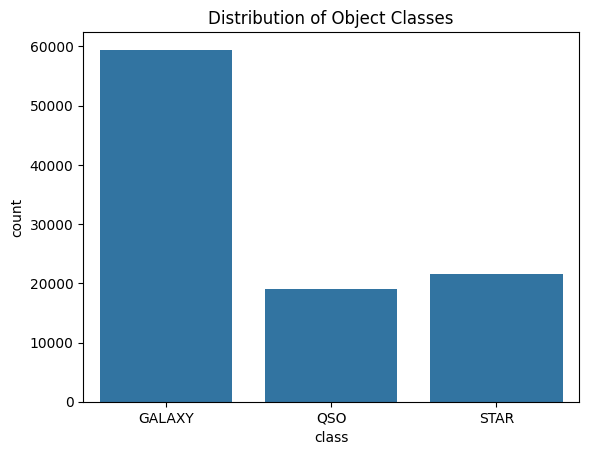

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='class')
plt.title('Distribution of Object Classes')
plt.show()

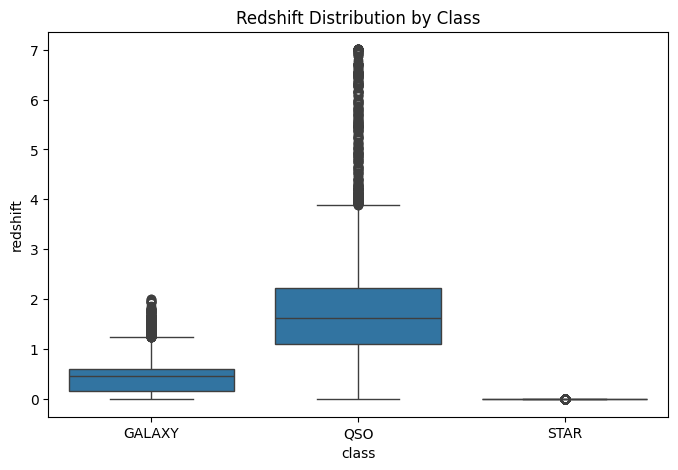

In [7]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='class', y='redshift')
plt.title('Redshift Distribution by Class')
plt.show()

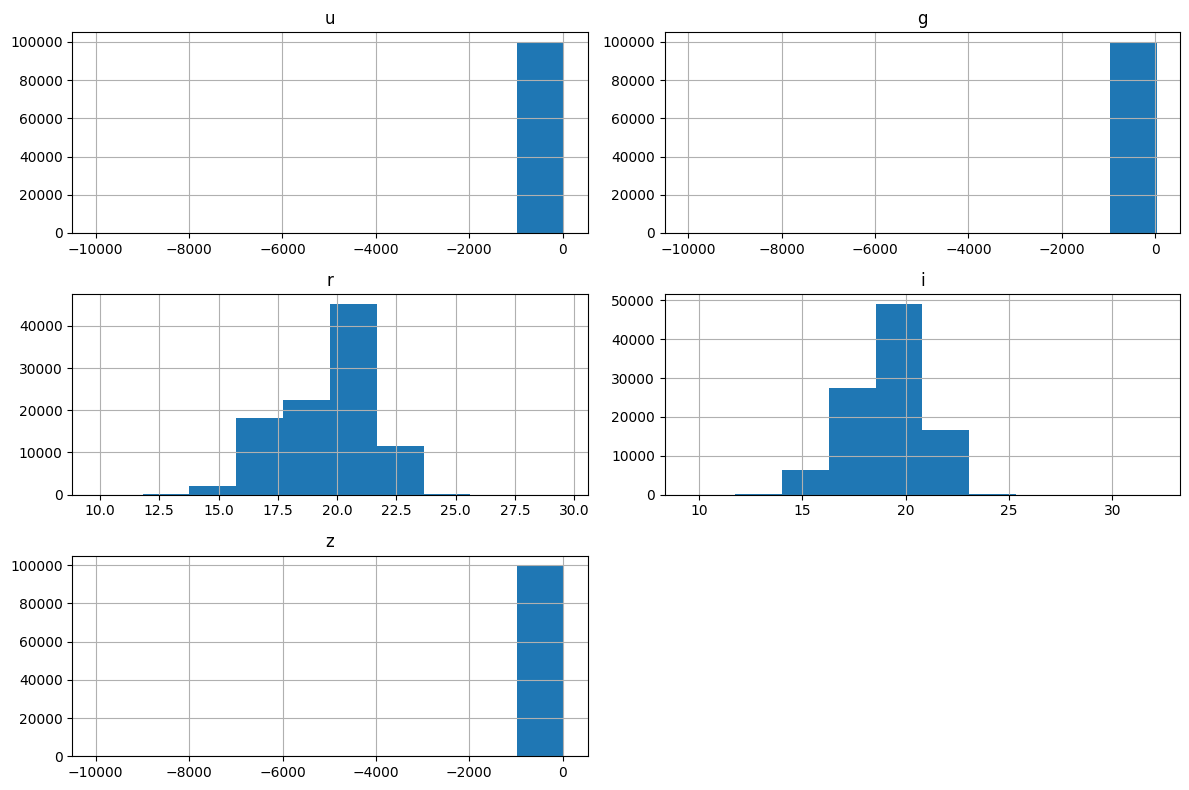

In [8]:
features = ['u', 'g', 'r', 'i', 'z']

df[features].hist(figsize=(12,8))
plt.tight_layout()
plt.show()

In [9]:
df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']

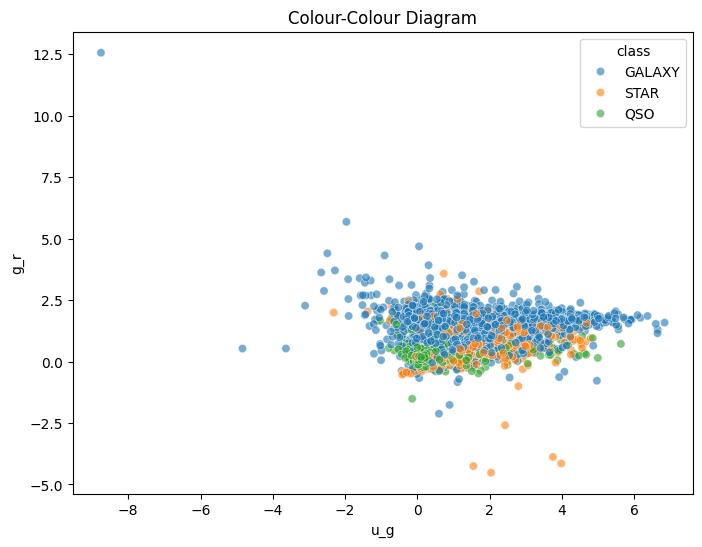

In [10]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df.sample(5000),
    x='u_g',
    y='g_r',
    hue='class',
    alpha=0.6
)

plt.title('Colour-Colour Diagram')
plt.show()

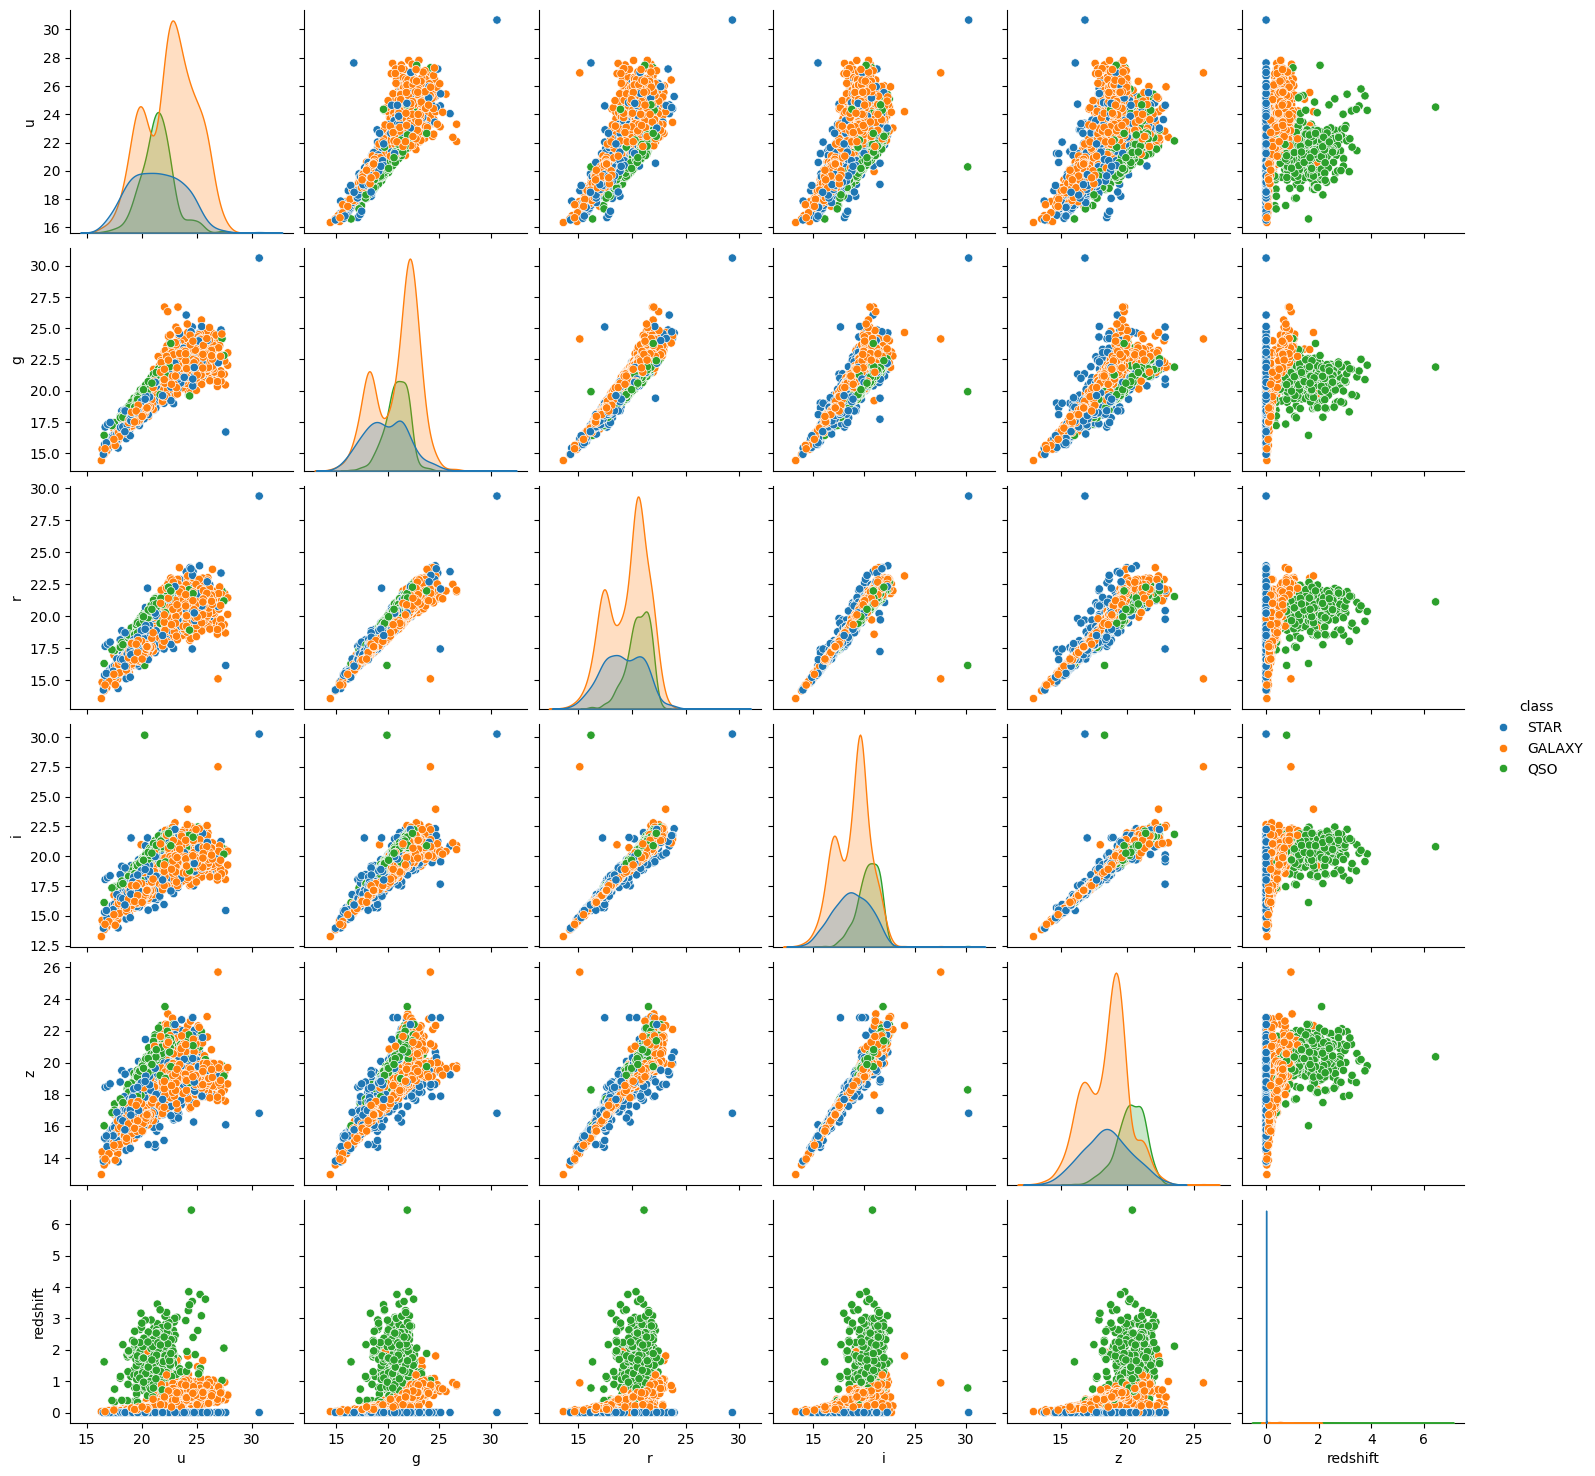

In [11]:
sample = df.sample(2000)

sns.pairplot(
    sample,
    vars=['u','g','r','i','z','redshift'],
    hue='class'
)

plt.show()